# FarmTech Solutions | Fase 6: Entrega 1 (YOLO customizada)

**Aluna:** Gabriele Brito Rocha Menezes | **RM:** rm574145

## 1. Objetivo

A FarmTech Solutions está expandindo seus serviços de IA para além do agronegócio, incluindo visão computacional. Este notebook simula uma demonstração para um cliente que quer entender, na prática, como funciona um sistema de detecção de objetos.

Treinamos uma **YOLO customizada** para reconhecer dois objetos bem diferentes entre si: **teclado** e **garrafa**. Foram feitos dois experimentos, com **30** e **60 épocas**, e comparamos precisão, recall, mAP, erro (loss), tempo de treino e tempo de inferência. O notebook cobre as três etapas pedidas: **treinamento, validação e teste**.

### Preparação do ambiente

A célula abaixo instala a biblioteca **Ultralytics** (que traz a YOLO). Antes de executar, ative a GPU em *Ambiente de execução → Alterar tipo de ambiente de execução → T4 GPU*.

In [ ]:
# Instala a biblioteca Ultralytics (YOLOv8), de forma silenciosa
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 7.8 MB/s eta 0:00:00


In [ ]:
import os, glob, time, shutil, subprocess        # utilitários de arquivos, tempo e sistema
import pandas as pd                              # tabelas de resultados
import matplotlib.pyplot as plt                  # gráficos de comparação
import torch                                     # usado para checar a GPU
from ultralytics import YOLO                     # biblioteca YOLO
from IPython.display import Image, display       # exibir as imagens processadas no notebook

# Confirma se a GPU está ativa (o treino fica muito mais rápido com ela)
print("GPU disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))         # nome da placa (ex.: Tesla T4)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU disponível: True
Tesla T4


O dataset fica no repositório do GitHub do grupo, para que o notebook rode em qualquer conta sem depender de um Drive pessoal. A célula clona o repositório e copia a pasta `dataset` para o disco local do Colab (leitura mais rápida que a do Drive). Se o clone falhar, ela usa a cópia do Google Drive como plano B.

In [ ]:
REPO_URL = "https://github.com/Gaby-britto/Grupo35-Fase6-VisaoComputacional.git"          # <<< TROQUE pelo link do repositório do grupo
DRIVE_DATASET = "/content/drive/MyDrive/fase6_entrega1/dataset"  # plano B: cópia do dataset no Drive
LOCAL = "/content/dataset"                                       # dataset no disco local do Colab
RUNS = "/content/runs"                                           # pasta onde os treinos são salvos

if not os.path.isdir(LOCAL):                                     # só baixa se ainda não existir
    try:
        # Clona o repositório sem pedir senha (repositório público)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/repo"], check=True,
                       env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
        shutil.copytree("/content/repo/dataset", LOCAL)           # copia só a pasta do dataset
        print("Dataset obtido do GitHub.")
    except Exception as erro:                                    # se o clone falhar, usa o Drive
        print("Clone falhou (", erro, ") -> usando o Google Drive.")
        from google.colab import drive
        drive.mount("/content/drive")                            # pede permissão de acesso ao Drive
        shutil.copytree(DRIVE_DATASET, LOCAL)                    # copia o dataset para o disco local

print("Conteúdo do dataset:", os.listdir(LOCAL))

Clone falhou ( Command '['git', 'clone', '--depth', '1', 'https://github.com/SEU_USUARIO/Grupo35.git', '/content/repo']' returned non-zero exit status 128. ) -> usando o Google Drive.
Mounted at /content/drive
Conteúdo do dataset: ['labels', 'data.yaml', 'images']


## 2. Dataset

Foram reunidas **80 imagens próprias**: 40 de teclado e 40 de garrafa. Para cada objeto, as imagens foram divididas em:

| Conjunto | Por classe | Total |
|---|---|---|
| Treino | 32 | 64 |
| Validação | 4 | 8 |
| Teste | 4 | 8 |

As fotos variam em ângulo, distância, fundo e iluminação, para o modelo não aprender apenas um tipo de cenário. As imagens de teste **não participam do treino nem da escolha do melhor modelo**, e servem apenas para a avaliação final.

A célula abaixo confere a quantidade de imagens em cada conjunto.

In [ ]:
EXT = (".jpg", ".jpeg", ".png")                                  # extensões de imagem aceitas

for conjunto in ["train", "val", "test"]:
    pasta = f"{LOCAL}/images/{conjunto}"                         # pasta do conjunto
    qtd = len([f for f in os.listdir(pasta) if f.lower().endswith(EXT)])   # conta só imagens
    print(f"{conjunto:>5}: {qtd} imagens")                       # esperado: 64, 8 e 8

train: 64 imagens
  val: 8 imagens
 test: 8 imagens


## 3. Organização dos arquivos

Os arquivos seguem o formato esperado pelo YOLO: uma pasta de imagens e uma de rótulos, separadas em treino e validação. O arquivo de rótulo tem o **mesmo nome** da imagem correspondente.

```
dataset/
├── data.yaml
├── images/   (train, val, test)
└── labels/   (train, val)
```

As imagens de teste ficam **sem rótulo**: servem para a inspeção visual das detecções.

In [ ]:
for conjunto in ["train", "val"]:
    # Nomes das imagens e dos rótulos, sem a extensão
    imgs = {os.path.splitext(f)[0] for f in os.listdir(f"{LOCAL}/images/{conjunto}") if f.lower().endswith(EXT)}
    lbls = {os.path.splitext(f)[0] for f in os.listdir(f"{LOCAL}/labels/{conjunto}") if f.endswith(".txt")}
    print(f"{conjunto}: {len(imgs)} imagens | {len(lbls)} rótulos")
    print("  imagens sem rótulo:", sorted(imgs - lbls))          # esperado: lista vazia
    print("  rótulos sem imagem:", sorted(lbls - imgs))          # esperado: lista vazia

train: 64 imagens | 64 rótulos
  imagens sem rótulo: []
  rótulos sem imagem: []
val: 8 imagens | 8 rótulos
  imagens sem rótulo: []
  rótulos sem imagem: []


## 4. Rotulação das imagens

As imagens de **treino** e de **validação** foram rotuladas no site [Make Sense](https://www.makesense.ai/), desenhando uma caixa (bounding box) ao redor de cada objeto e exportando no **formato YOLO**.

Cada linha do arquivo `.txt` tem o formato `classe x_centro y_centro largura altura`, com valores entre 0 e 1:

| ID | Classe |
|---|---|
| 0 | teclado |
| 1 | garrafa |

As imagens de validação também precisaram de rótulo, porque é com elas que o YOLO calcula precisão, recall e mAP durante o treino.

A célula abaixo confere os rótulos: quantos objetos há de cada classe e se todos os valores estão entre 0 e 1.

In [ ]:
NOMES = {0: "teclado", 1: "garrafa"}                             # ID da classe -> nome

for conjunto in ["train", "val"]:
    contagem = {0: 0, 1: 0}                                      # objetos por classe
    for arq in glob.glob(f"{LOCAL}/labels/{conjunto}/*.txt"):
        with open(arq) as f:
            for linha in f:
                partes = linha.split()                           # classe x y largura altura
                if not partes:
                    continue                                     # ignora linhas vazias
                contagem[int(partes[0])] += 1                    # soma 1 objeto na classe
                # Garante que as coordenadas estão normalizadas (entre 0 e 1)
                assert all(0 <= float(v) <= 1 for v in partes[1:]), f"valor fora de 0-1 em {arq}"
    print(conjunto, {NOMES[k]: v for k, v in contagem.items()})

# Mostra o rótulo de um exemplo, para ilustrar o formato
exemplo = sorted(glob.glob(f"{LOCAL}/labels/train/*.txt"))[0]
print("\nExemplo:", os.path.basename(exemplo))
print(open(exemplo).read())

train {'teclado': 34, 'garrafa': 32}
val {'teclado': 4, 'garrafa': 4}

Exemplo: garrafa_001.txt
1 0.498025 0.498148 0.350617 0.418519


## 5. Configuração da YOLO

Usamos a biblioteca **Ultralytics** com o modelo **YOLOv8n** (a versão menor e mais rápida), partindo de pesos pré-treinados (*transfer learning*). Essa escolha é adequada para um dataset pequeno, porque a rede já traz conhecimento de formas e bordas e só precisa se ajustar às nossas duas classes.

O arquivo `data.yaml` informa à YOLO onde estão as imagens e quais são as classes. Os dois treinos usam **exatamente a mesma configuração** (`imgsz=640`, `batch=8`, `seed=42`), mudando apenas o número de épocas, para que a comparação seja justa.

In [ ]:
# Conteúdo do data.yaml: caminho do dataset, pastas e nomes das classes
yaml_texto = f"""path: {LOCAL}
train: images/train
val: images/val
test: images/test
names:
  0: teclado
  1: garrafa
"""
DATA = f"{LOCAL}/data.yaml"                                      # caminho do arquivo de configuração
with open(DATA, "w") as f:
    f.write(yaml_texto)                                          # grava o arquivo
print(yaml_texto)

path: /content/dataset
train: images/train
val: images/val
test: images/test
names:
  0: teclado
  1: garrafa



Para garantir que os dois treinos sejam idênticos, exceto pelo número de épocas, criamos funções reutilizáveis de **treino**, **validação** e **teste**.

In [ ]:
def treinar(epocas):
    """Treina a YOLOv8n por `epocas` épocas e devolve (pasta dos resultados, tempo em minutos)."""
    modelo = YOLO("yolov8n.pt")                                  # sempre parte do mesmo modelo pré-treinado
    t0 = time.time()                                             # marca o início
    modelo.train(
        data=DATA,                                               # configuração do dataset
        epochs=epocas,                                           # única coisa que muda entre os experimentos
        imgsz=640,                                               # tamanho da imagem
        batch=8,                                                 # imagens por lote
        seed=42,                                                 # semente fixa, para repetir o resultado
        project=RUNS,                                            # pasta de saída
        name=f"treino_{epocas}ep",                               # nome da execução
        workers=2,                                               # processos de leitura de dados
        exist_ok=True,                                           # sobrescreve em vez de criar pastas "-2"
    )
    tempo_min = (time.time() - t0) / 60                          # duração total em minutos
    return str(modelo.trainer.save_dir), tempo_min


def validar(modelo, nome):
    """Valida o modelo nas imagens de validação e devolve (tabela por classe, métricas gerais)."""
    r = modelo.val(data=DATA, split="val", plots=True, verbose=False,
                   project=RUNS, name=f"val_{nome}", exist_ok=True)
    linhas = [{"Classe": "Todas", "Precisão": r.box.mp, "Recall": r.box.mr,
               "mAP50": r.box.map50, "mAP50-95": r.box.map}]     # linha com a média geral
    for i, cls in enumerate(r.box.ap_class_index):               # uma linha por classe
        linhas.append({"Classe": r.names[int(cls)], "Precisão": r.box.p[i], "Recall": r.box.r[i],
                       "mAP50": r.box.ap50[i], "mAP50-95": r.box.ap[i]})
    tabela = pd.DataFrame(linhas).round(3)
    geral = {"precisao": r.box.mp, "recall": r.box.mr, "mAP50": r.box.map50, "mAP50-95": r.box.map}
    return tabela, geral


def testar(modelo, nome):
    """Aplica o modelo nas imagens de teste. Devolve (tabela de detecções, pasta com as imagens)."""
    res = modelo.predict(source=f"{LOCAL}/images/test", conf=0.25, save=True,
                         project=RUNS, name=f"teste_{nome}", exist_ok=True, verbose=False)
    linhas = []
    for r in res:
        arq = os.path.basename(r.path)                           # nome da imagem
        dets = [f"{r.names[int(c)]} ({float(s):.2f})"            # classe e confiança de cada caixa
                for c, s in zip(r.boxes.cls, r.boxes.conf)]
        real = next((n for n in NOMES.values() if n in arq.lower()), "ver imagem")  # classe pelo nome do arquivo
        linhas.append({"Imagem": arq, "Objeto real": real,
                       "Detectado": ", ".join(dets) if dets else "nada detectado"})
    return pd.DataFrame(linhas), str(res[0].save_dir)

## 6. Treino com 30 épocas

Primeiro experimento: **30 épocas**. O resultado de cada época (losses e métricas de validação) é salvo em `results.csv`, e o melhor modelo é salvo em `best.pt`.

Nas primeiras épocas as métricas ficam próximas de zero. Isso é esperado: o YOLO usa um período de *warmup* e o dataset é pequeno. A partir da metade do treino o modelo passa a aprender de forma consistente.

In [ ]:
pasta30, tempo30 = treinar(30)                                   # treina com 30 épocas
print(f"\nTempo de treino (30 épocas): {tempo30:.1f} min")
print("Resultados salvos em:", pasta30)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino_30ep, nbs=64, nms=None, opset=None, optimize=False, optimi

## 7. Validação do modelo de 30 épocas

Validação nas **8 imagens de validação** (4 de cada classe), usando o `best.pt` do treino.

**Como ler:** *precisão* mostra quantas das detecções feitas estavam corretas; *recall* mostra quantos dos objetos reais foram encontrados; *mAP50* e *mAP50-95* resumem a qualidade das caixas.

*Nota:* o `best.pt` não guarda necessariamente a época com maior mAP50. O Ultralytics escolhe a melhor época por uma nota que dá 90% de peso ao mAP50-95 e 10% ao mAP50. Por isso os números do `best.pt` podem diferir dos da última época.

In [ ]:
modelo30 = YOLO(f"{pasta30}/weights/best.pt")                    # carrega o melhor modelo do treino de 30 épocas
tab_val30, geral30 = validar(modelo30, "30ep")                   # valida nas imagens de validação
display(tab_val30)                                               # tabela por classe

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3052.3±579.9 MB/s, size: 274.5 KB)
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 2.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.7it/s 0.3s
                   all          8          8       0.91      0.981      0.995      0.511
Speed: 0.4ms preprocess, 7.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/val_30ep


,Classe,Precisão,Recall,mAP50,mAP50-95
0,Todas,0.910,0.981,0.995,0.511
1,teclado,1.000,0.962,0.995,0.482
2,garrafa,0.819,1.000,0.995,0.539


**Leitura:** o modelo de 30 épocas encontrou praticamente todos os objetos da validação (recall de 0,98) e atingiu mAP50 de 0,995. O teclado teve precisão de 1,0; a garrafa teve precisão menor (0,82), ou seja, houve algumas detecções a mais. Como o `best.pt` é a melhor época justamente nessas 8 imagens, valores tão próximos de 1,0 podem estar um pouco otimistas.

## 8. Teste com as imagens reservadas

Aplicamos o modelo de 30 épocas nas **8 imagens de teste**, que nunca participaram do treino. Usamos limiar de confiança de 0,25: só aparecem caixas com confiança igual ou maior que 25%.

In [ ]:
tab_teste30, pasta_teste30 = testar(modelo30, "30ep")            # detecta nas 8 imagens de teste
display(tab_teste30)                                             # o que foi detectado em cada imagem

Results saved to /content/runs/teste_30ep


,Imagem,Objeto real,Detectado
0,Cópia de 0A023RGKPT03.jpg,ver imagem,teclado (0.44)
1,Cópia de 0AZZXPBJK39G.jpg,ver imagem,"teclado (0.32), teclado (0.26)"
2,Cópia de 0I7KT8GRVA67.jpg,ver imagem,nada detectado
3,Cópia de 0IUTJE8DMIXM.jpg,ver imagem,teclado (0.68)
4,Cópia de WhatsApp Image 2026-10-07 at 17.18.3...,ver imagem,garrafa (0.98)
5,Cópia de WhatsApp Image 2026-10-07 at 17.18.3...,ver imagem,garrafa (0.99)
6,Cópia de WhatsApp Image 2026-10-07 at 17.18.4...,ver imagem,garrafa (0.68)
7,Cópia de WhatsApp Image 2026-10-07 at 17.18.4...,ver imagem,nada detectado


## 9. Treino com 60 épocas

Segundo experimento, **idêntico ao primeiro, exceto pelo número de épocas (60)**. O modelo parte novamente dos pesos pré-treinados, para a comparação ser justa. Em seguida, repetimos a validação e o teste.

In [ ]:
pasta60, tempo60 = treinar(60)                                   # treina com 60 épocas
print(f"\nTempo de treino (60 épocas): {tempo60:.1f} min")
print("Resultados salvos em:", pasta60)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino_60ep, nbs=64, nms=None, opset=None, optimize=False, optimi

In [ ]:
modelo60 = YOLO(f"{pasta60}/weights/best.pt")                    # carrega o melhor modelo do treino de 60 épocas
tab_val60, geral60 = validar(modelo60, "60ep")                   # valida nas imagens de validação
display(tab_val60)                                               # tabela por classe

tab_teste60, pasta_teste60 = testar(modelo60, "60ep")            # detecta nas 8 imagens de teste
display(tab_teste60)                                             # o que foi detectado em cada imagem

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3822.2±939.0 MB/s, size: 277.3 KB)
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 2.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s
                   all          8          8      0.969       0.75      0.912      0.514
Speed: 0.4ms preprocess, 7.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/val_60ep


,Classe,Precisão,Recall,mAP50,mAP50-95
0,Todas,0.969,0.75,0.912,0.514
1,teclado,0.953,0.75,0.912,0.530
2,garrafa,0.985,0.75,0.912,0.498


Results saved to /content/runs/teste_60ep


,Imagem,Objeto real,Detectado
0,Cópia de 0A023RGKPT03.jpg,ver imagem,teclado (0.95)
1,Cópia de 0AZZXPBJK39G.jpg,ver imagem,teclado (0.96)
2,Cópia de 0I7KT8GRVA67.jpg,ver imagem,nada detectado
3,Cópia de 0IUTJE8DMIXM.jpg,ver imagem,"teclado (0.90), teclado (0.29)"
4,Cópia de WhatsApp Image 2026-10-07 at 17.18.3...,ver imagem,garrafa (0.90)
5,Cópia de WhatsApp Image 2026-10-07 at 17.18.3...,ver imagem,garrafa (0.92)
6,Cópia de WhatsApp Image 2026-10-07 at 17.18.4...,ver imagem,garrafa (0.78)
7,Cópia de WhatsApp Image 2026-10-07 at 17.18.4...,ver imagem,"garrafa (0.63), garrafa (0.33)"


## 10. Comparação: 30 x 60 épocas

Comparamos os dois experimentos em três frentes: **erro (loss) ao longo do treino**, **métricas de validação** e **desempenho** (tempo de treino e de inferência).

Nos gráficos, a linha contínua é a loss de **treino** e a tracejada a de **validação**. Se a de treino continua caindo e a de validação para de cair ou sobe, o modelo está começando a decorar as imagens de treino (**overfitting**).

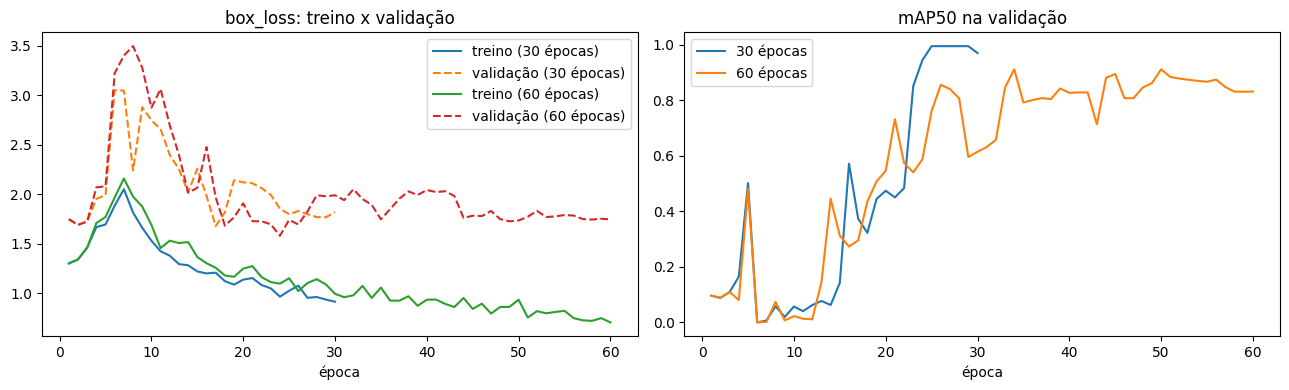

In [ ]:
# Lê o histórico de cada treino (uma linha por época)
d30 = pd.read_csv(f"{pasta30}/results.csv"); d30.columns = d30.columns.str.strip()
d60 = pd.read_csv(f"{pasta60}/results.csv"); d60.columns = d60.columns.str.strip()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))                    # dois gráficos lado a lado
for d, nome in [(d30, "30 épocas"), (d60, "60 épocas")]:
    ax[0].plot(d["epoch"], d["train/box_loss"], label=f"treino ({nome})")        # loss de treino
    ax[0].plot(d["epoch"], d["val/box_loss"], "--", label=f"validação ({nome})") # loss de validação
    ax[1].plot(d["epoch"], d["metrics/mAP50(B)"], label=nome)                    # mAP50 por época
ax[0].set_title("box_loss: treino x validação"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].set_title("mAP50 na validação"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
def resumo(d, geral, tempo, nome):
    """Monta uma linha de resumo com o melhor ponto (best.pt) e a última época do treino."""
    ult = d.iloc[-1]                                             # última época
    i = d["metrics/mAP50(B)"].idxmax()                           # época com maior mAP50
    return {"Treino": nome,
            "Tempo de treino (min)": round(tempo, 1),
            "best.pt: Precisão": round(geral["precisao"], 3),
            "best.pt: Recall": round(geral["recall"], 3),
            "best.pt: mAP50": round(geral["mAP50"], 3),
            "best.pt: mAP50-95": round(geral["mAP50-95"], 3),
            "Última época: mAP50": round(ult["metrics/mAP50(B)"], 3),
            "Melhor mAP50 (época)": f'{d.loc[i, "metrics/mAP50(B)"]:.3f} ({int(d.loc[i, "epoch"])})',
            "Loss treino (box/cls)": f'{ult["train/box_loss"]:.3f} / {ult["train/cls_loss"]:.3f}',
            "Loss validação (box/cls)": f'{ult["val/box_loss"]:.3f} / {ult["val/cls_loss"]:.3f}'}

tabela_comp = pd.DataFrame([resumo(d30, geral30, tempo30, "30 épocas"),
                            resumo(d60, geral60, tempo60, "60 épocas")]).set_index("Treino").T
display(tabela_comp)                                             # tabela comparativa (transposta para leitura)

Treino,30 épocas,60 épocas
Tempo de treino (min),1.2,1.6
best.pt: Precisão,0.91,0.969
best.pt: Recall,0.981,0.75
best.pt: mAP50,0.995,0.912
best.pt: mAP50-95,0.511,0.514
Última época: mAP50,0.97,0.832
Melhor mAP50 (época),0.995 (25),0.912 (34)
Loss treino (box/cls),0.913 / 1.187,0.704 / 0.754
Loss validação (box/cls),1.818 / 1.614,1.745 / 1.382


In [ ]:
imgs_teste = sorted(glob.glob(f"{LOCAL}/images/test/*"))         # imagens de teste

def tempo_inferencia(modelo, repeticoes=3):
    """Tempo médio por imagem (ms), incluindo leitura do arquivo."""
    modelo.predict(imgs_teste[0], verbose=False)                 # aquecimento da GPU (não conta no tempo)
    t0 = time.time()
    for _ in range(repeticoes):
        modelo.predict(imgs_teste, verbose=False)                # prediz nas 8 imagens
    return (time.time() - t0) / (repeticoes * len(imgs_teste)) * 1000

print(f"Inferência, 30 épocas: {tempo_inferencia(modelo30):.1f} ms/imagem")
print(f"Inferência, 60 épocas: {tempo_inferencia(modelo60):.1f} ms/imagem")

Inferência, 30 épocas: 21.3 ms/imagem
Inferência, 60 épocas: 21.0 ms/imagem


### Ganhos, limitações e sinais de overfitting

- **Resultado principal:** na validação, 60 épocas **não superaram** 30 épocas. O melhor mAP50 foi **0,995** (época 25) com 30 épocas e **0,912** (época 34) com 60. No `best.pt`, o recall foi de 0,98 contra 0,75 (6 de 8 objetos), a precisão foi de 0,91 contra 0,97, e o mAP50-95 ficou praticamente igual (0,511 e 0,514).
- **Sem ganho nas épocas extras:** no treino de 60 épocas, o mAP50 sobe até a época ~34, depois oscila e termina em 0,83, abaixo do pico.
- **Sinal leve de overfitting:** a loss de treino continua caindo (box_loss de ~0,70 no final), enquanto a de validação estaciona entre ~1,7 e ~2,0 e não acompanha. A distância entre as duas curvas indica que o modelo passa a se ajustar mais às imagens de treino do que às novas.
- **Teste:** o modelo de 60 épocas deu confianças bem mais altas e achou a garrafa deitada que o de 30 perdeu, mas gerou caixas extras e uma caixa imprecisa (detalhes na seção 11).
- **Desempenho:** o treino levou 1,2 min com 30 épocas e 1,6 min com 60. O tempo de inferência é praticamente o mesmo nos dois (~21 ms por imagem, incluindo a leitura do arquivo), como esperado, já que a arquitetura é a mesma.
- **Limitação principal:** a validação tem só **8 imagens e 8 objetos**. Um único acerto ou erro altera o recall em 0,125. Como evidência da instabilidade, uma execução anterior do mesmo experimento de 30 épocas, em outra sessão, teve mAP50 de 0,76 (contra 0,995 aqui), mesmo com a mesma semente. As diferenças entre os modelos devem ser lidas como tendência, e não como prova.

## 11. Prints das imagens de teste processadas

As imagens abaixo mostram o que cada modelo detectou nas imagens de teste, com a caixa, o nome da classe e a confiança.

**Modelo de 30 épocas**

Cópia de 0A023RGKPT03.jpg


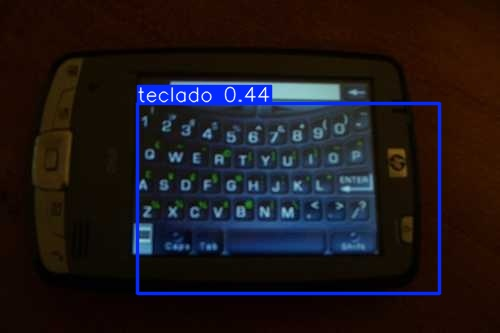

Cópia de 0AZZXPBJK39G.jpg


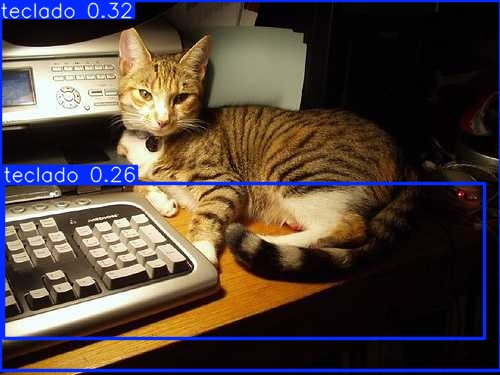

Cópia de 0I7KT8GRVA67.jpg


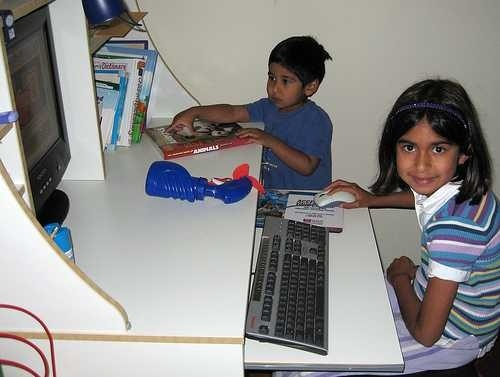

Cópia de 0IUTJE8DMIXM.jpg


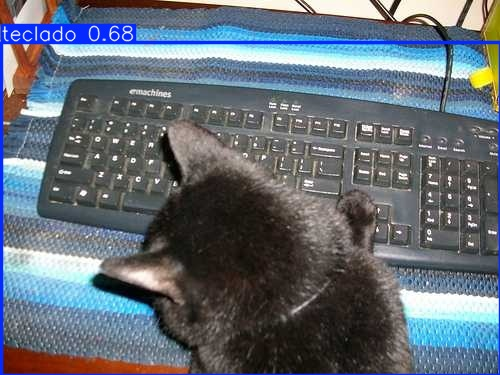

Cópia de WhatsApp Image 2026-10-07 at 17.18.37 (1).jpg


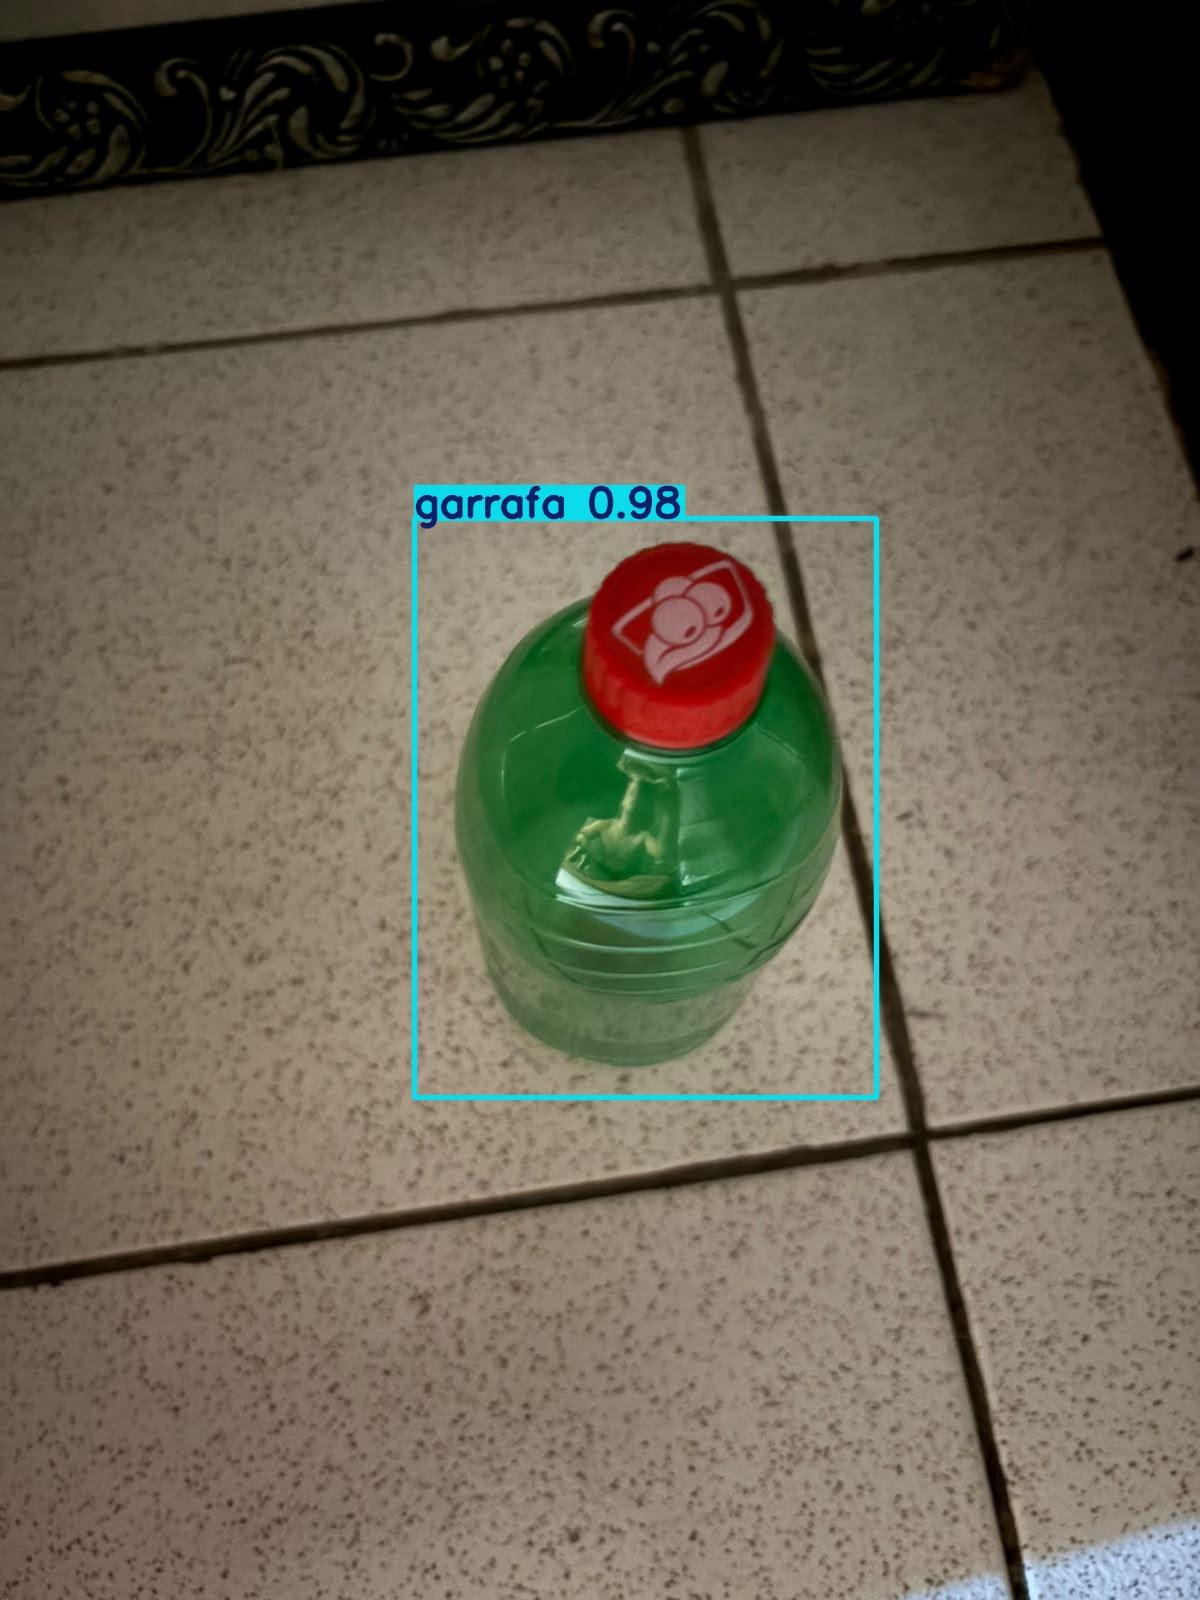

Cópia de WhatsApp Image 2026-10-07 at 17.18.39 (4).jpg


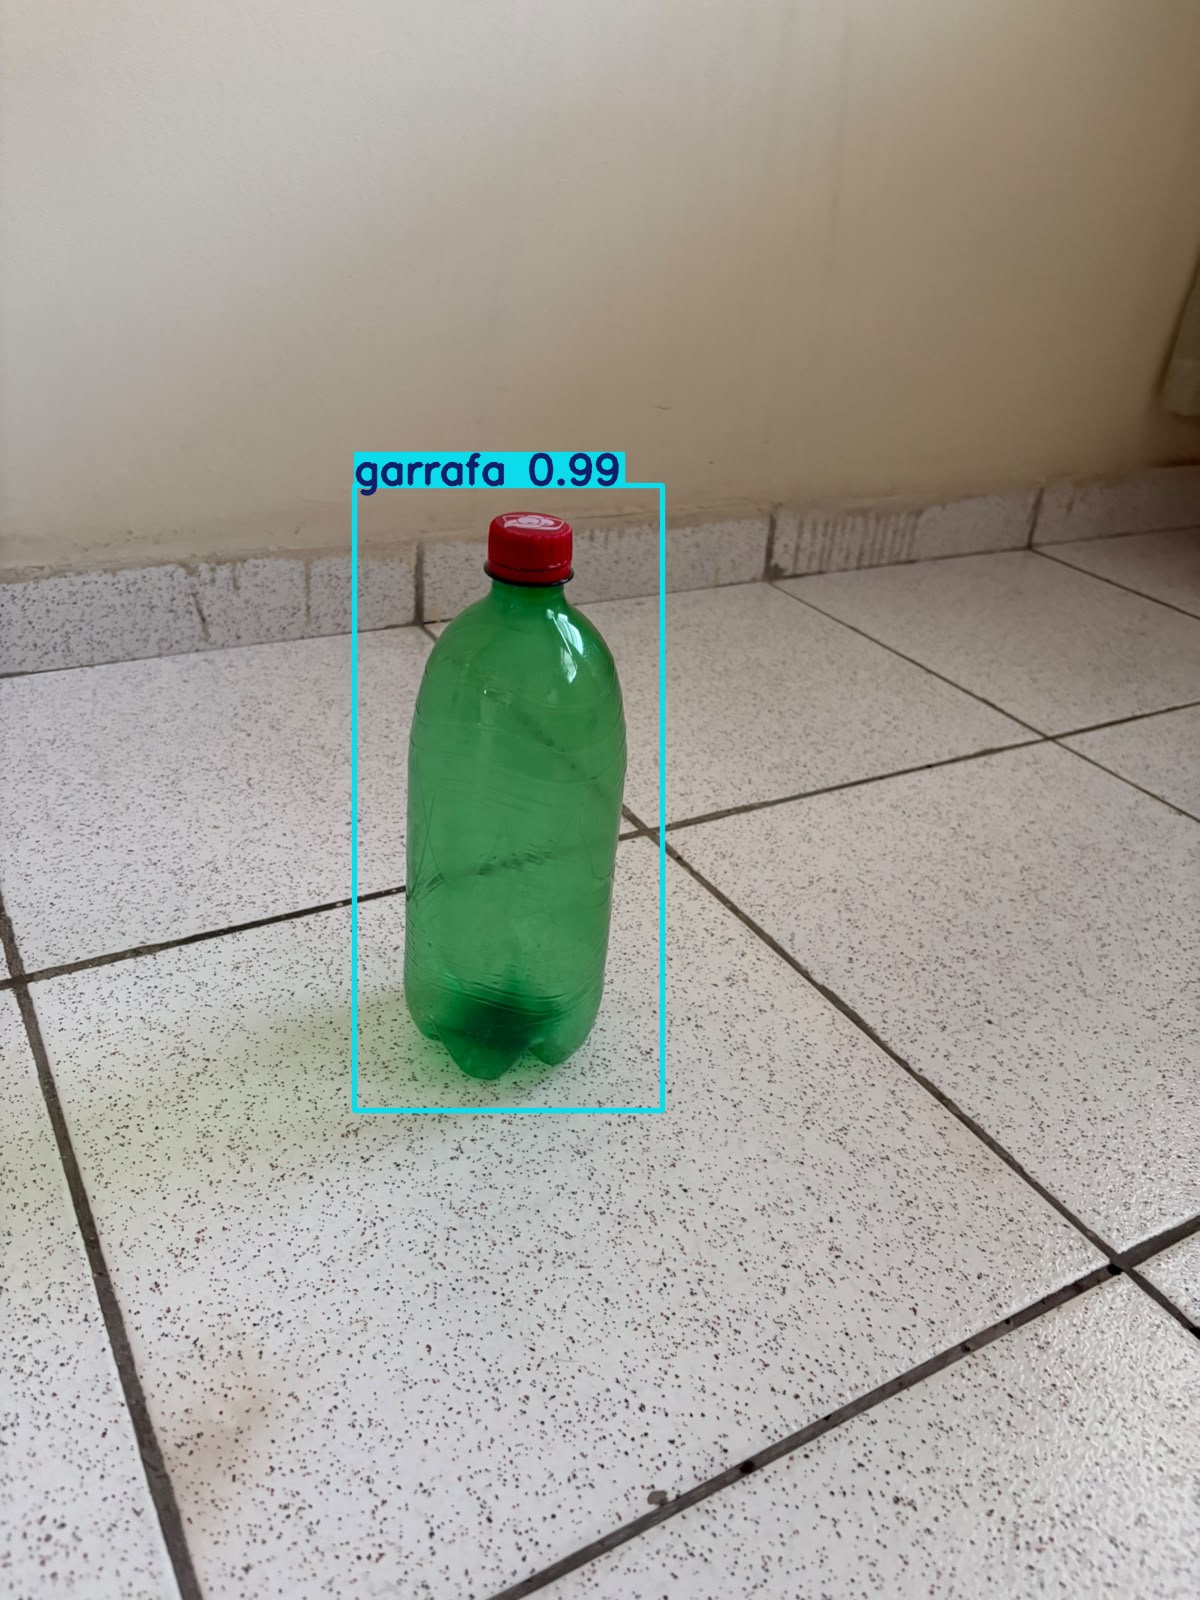

Cópia de WhatsApp Image 2026-10-07 at 17.18.41.jpg


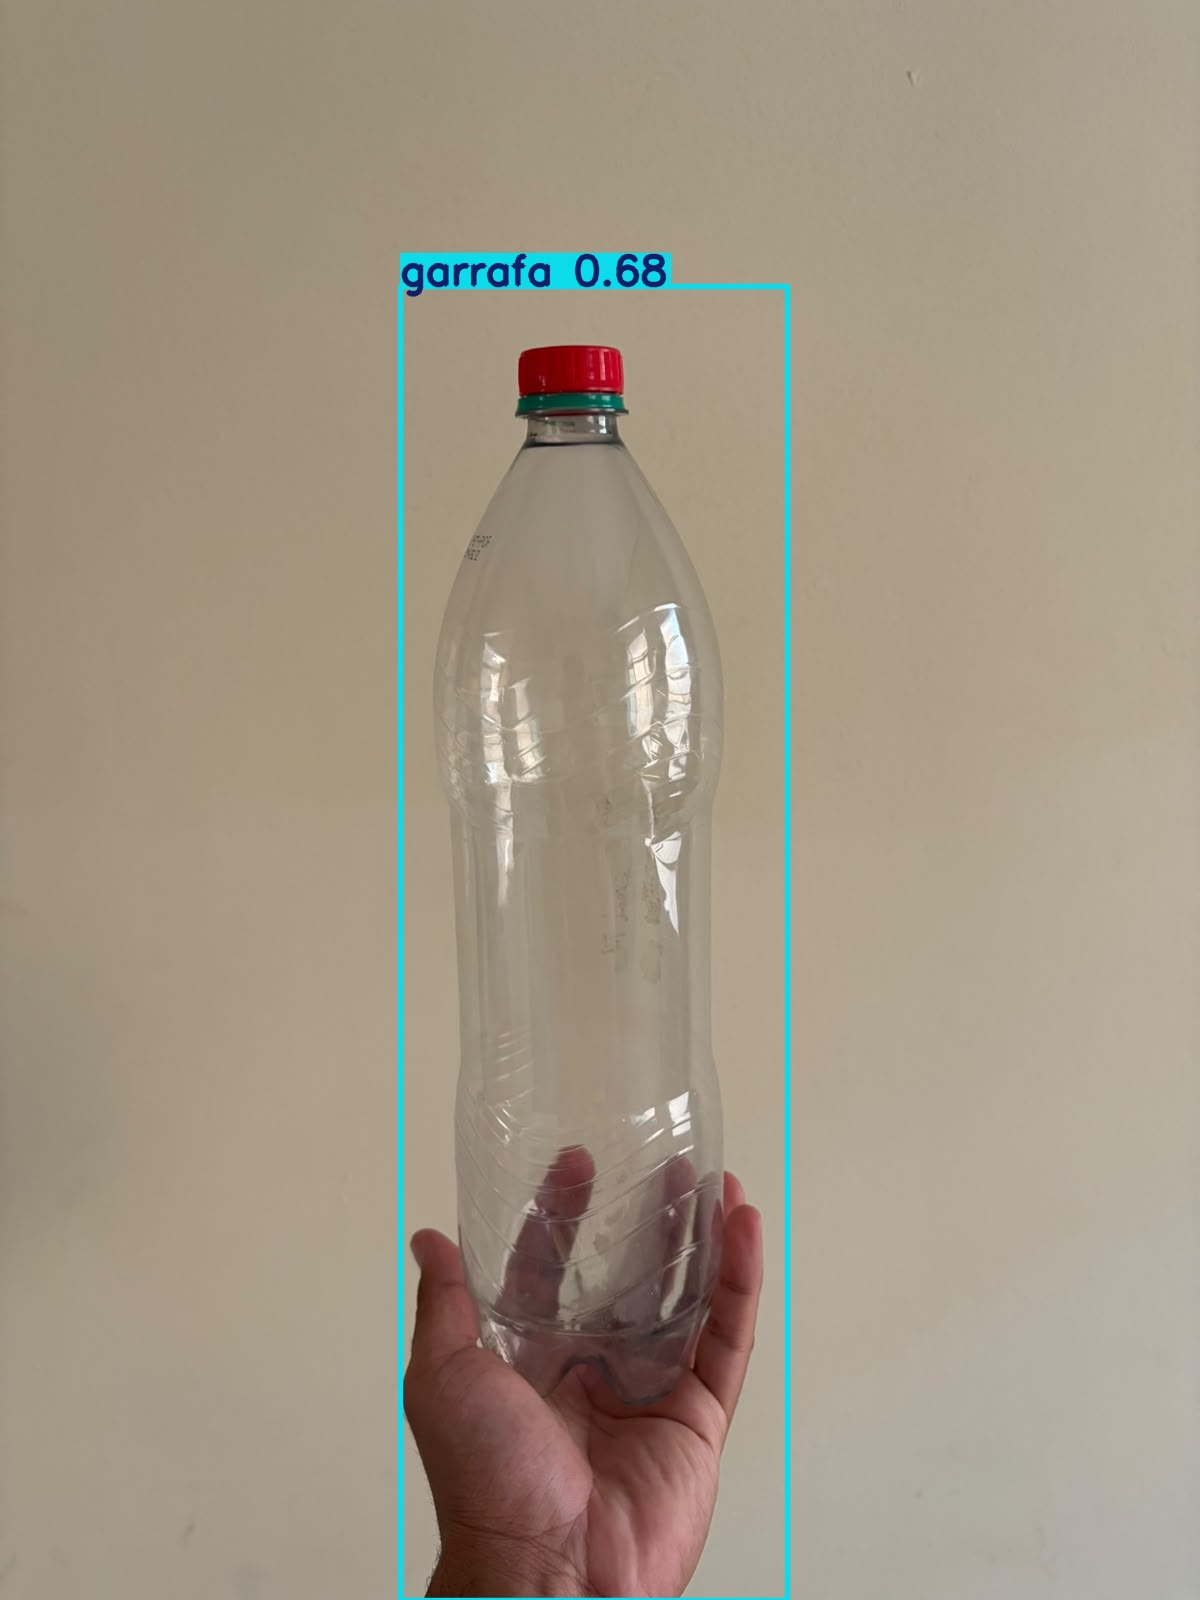

Cópia de WhatsApp Image 2026-10-07 at 17.18.42 (2).jpg


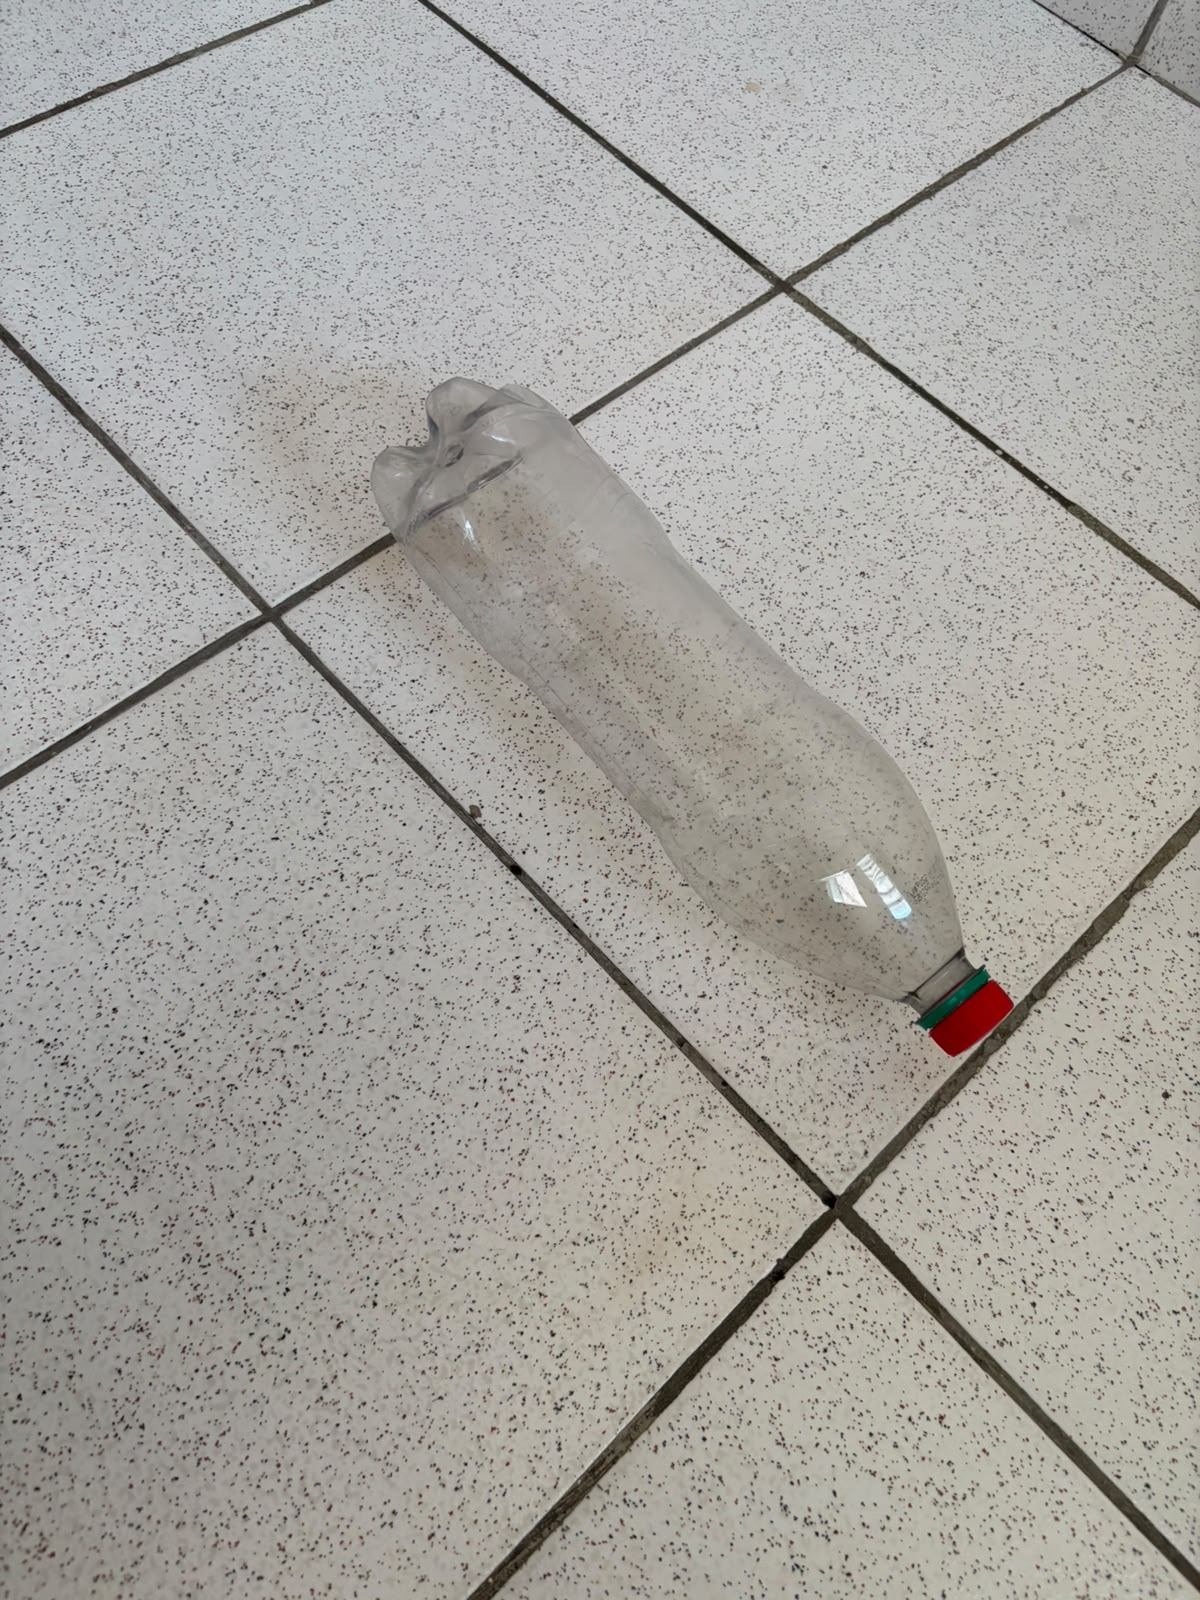

In [ ]:
for arq in sorted(glob.glob(f"{pasta_teste30}/*.jp*g") + glob.glob(f"{pasta_teste30}/*.png")):
    print(os.path.basename(arq))                                 # nome da imagem
    display(Image(arq, width=500))                               # imagem com as caixas desenhadas

**Modelo de 60 épocas**

Cópia de 0A023RGKPT03.jpg


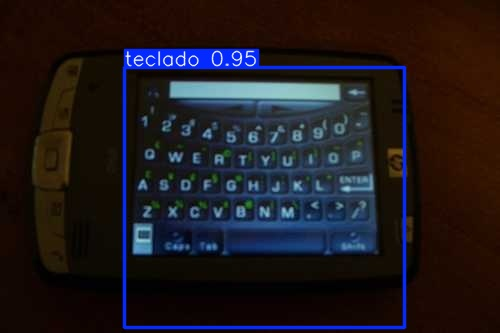

Cópia de 0AZZXPBJK39G.jpg


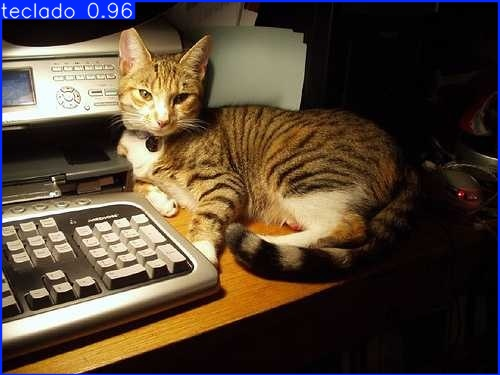

Cópia de 0I7KT8GRVA67.jpg


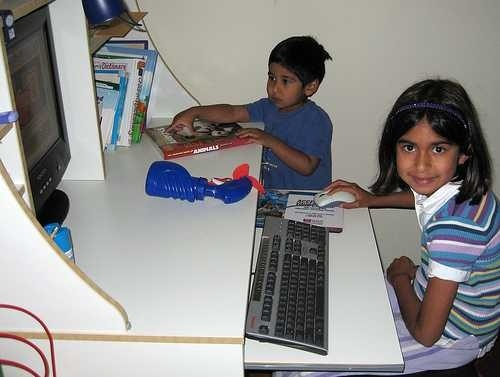

Cópia de 0IUTJE8DMIXM.jpg


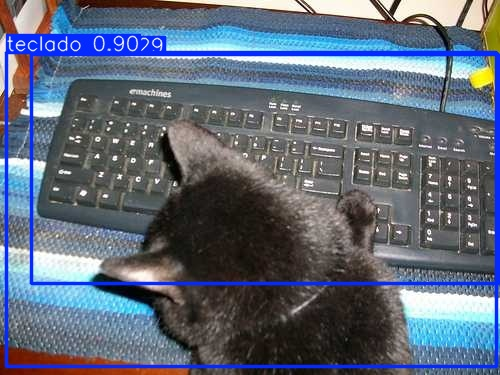

Cópia de WhatsApp Image 2026-10-07 at 17.18.37 (1).jpg


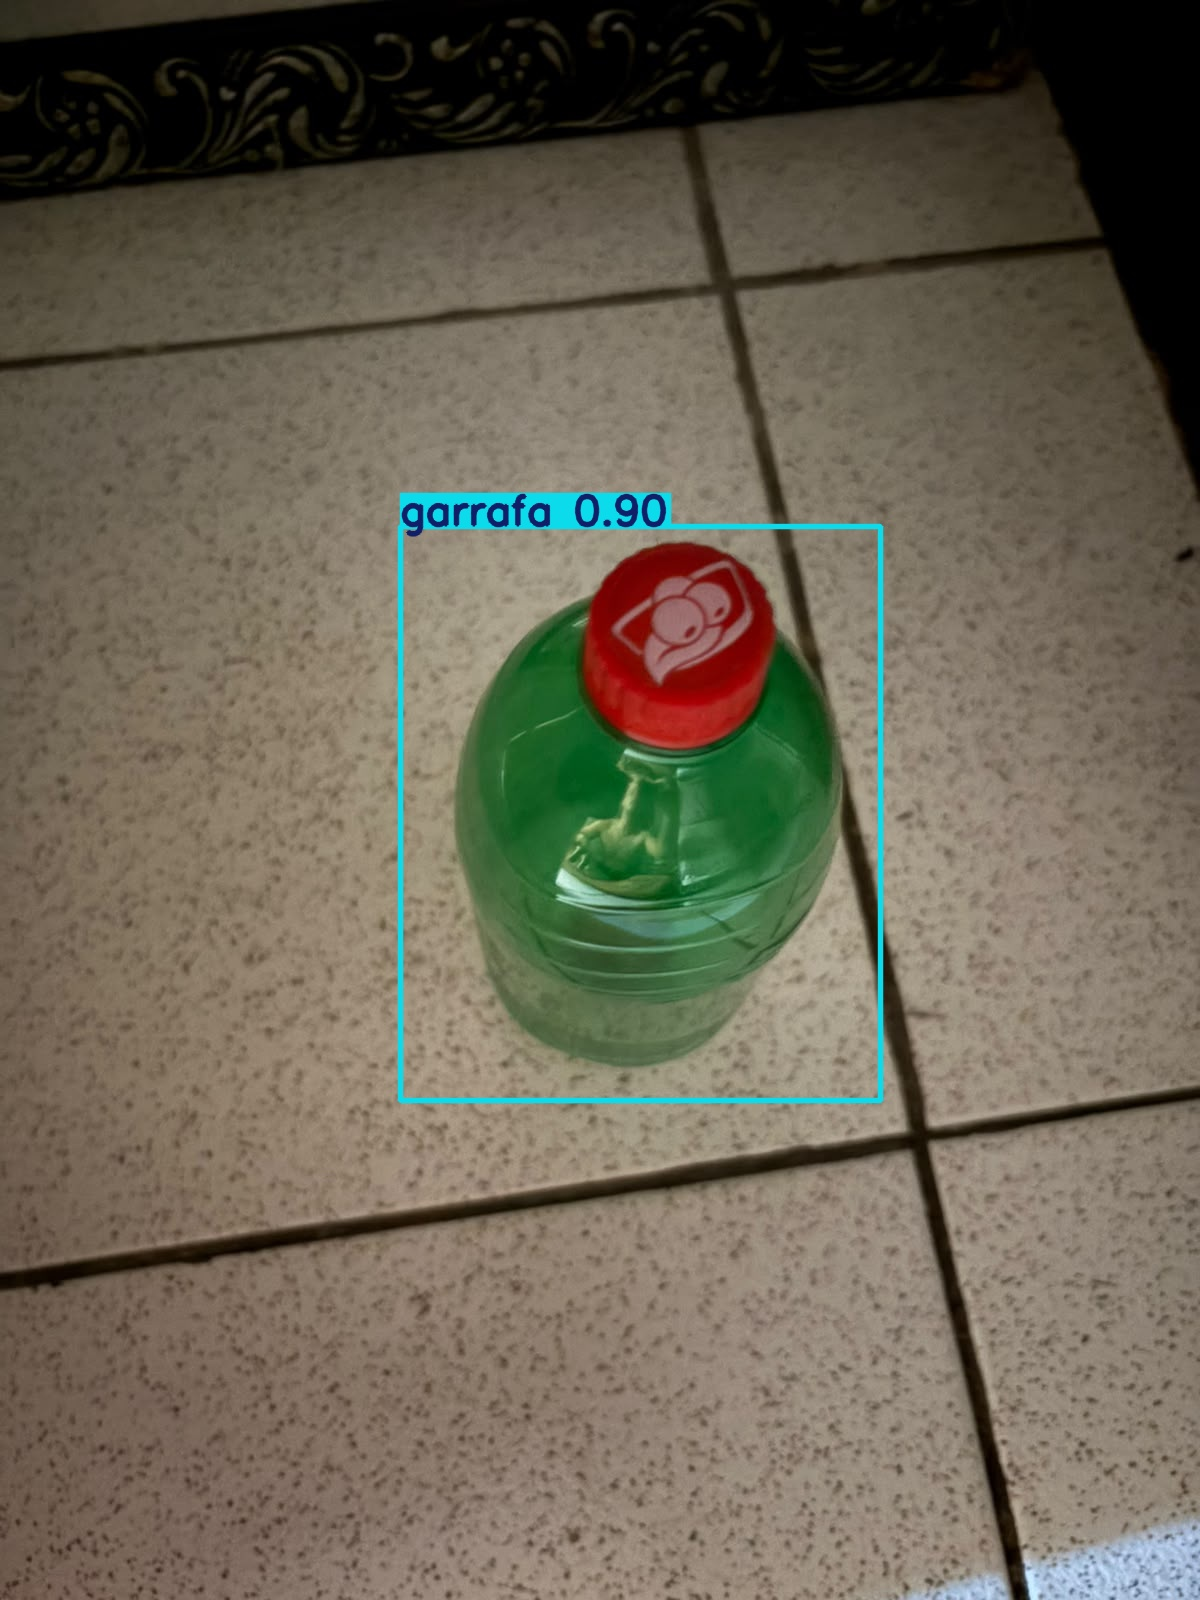

Cópia de WhatsApp Image 2026-10-07 at 17.18.39 (4).jpg


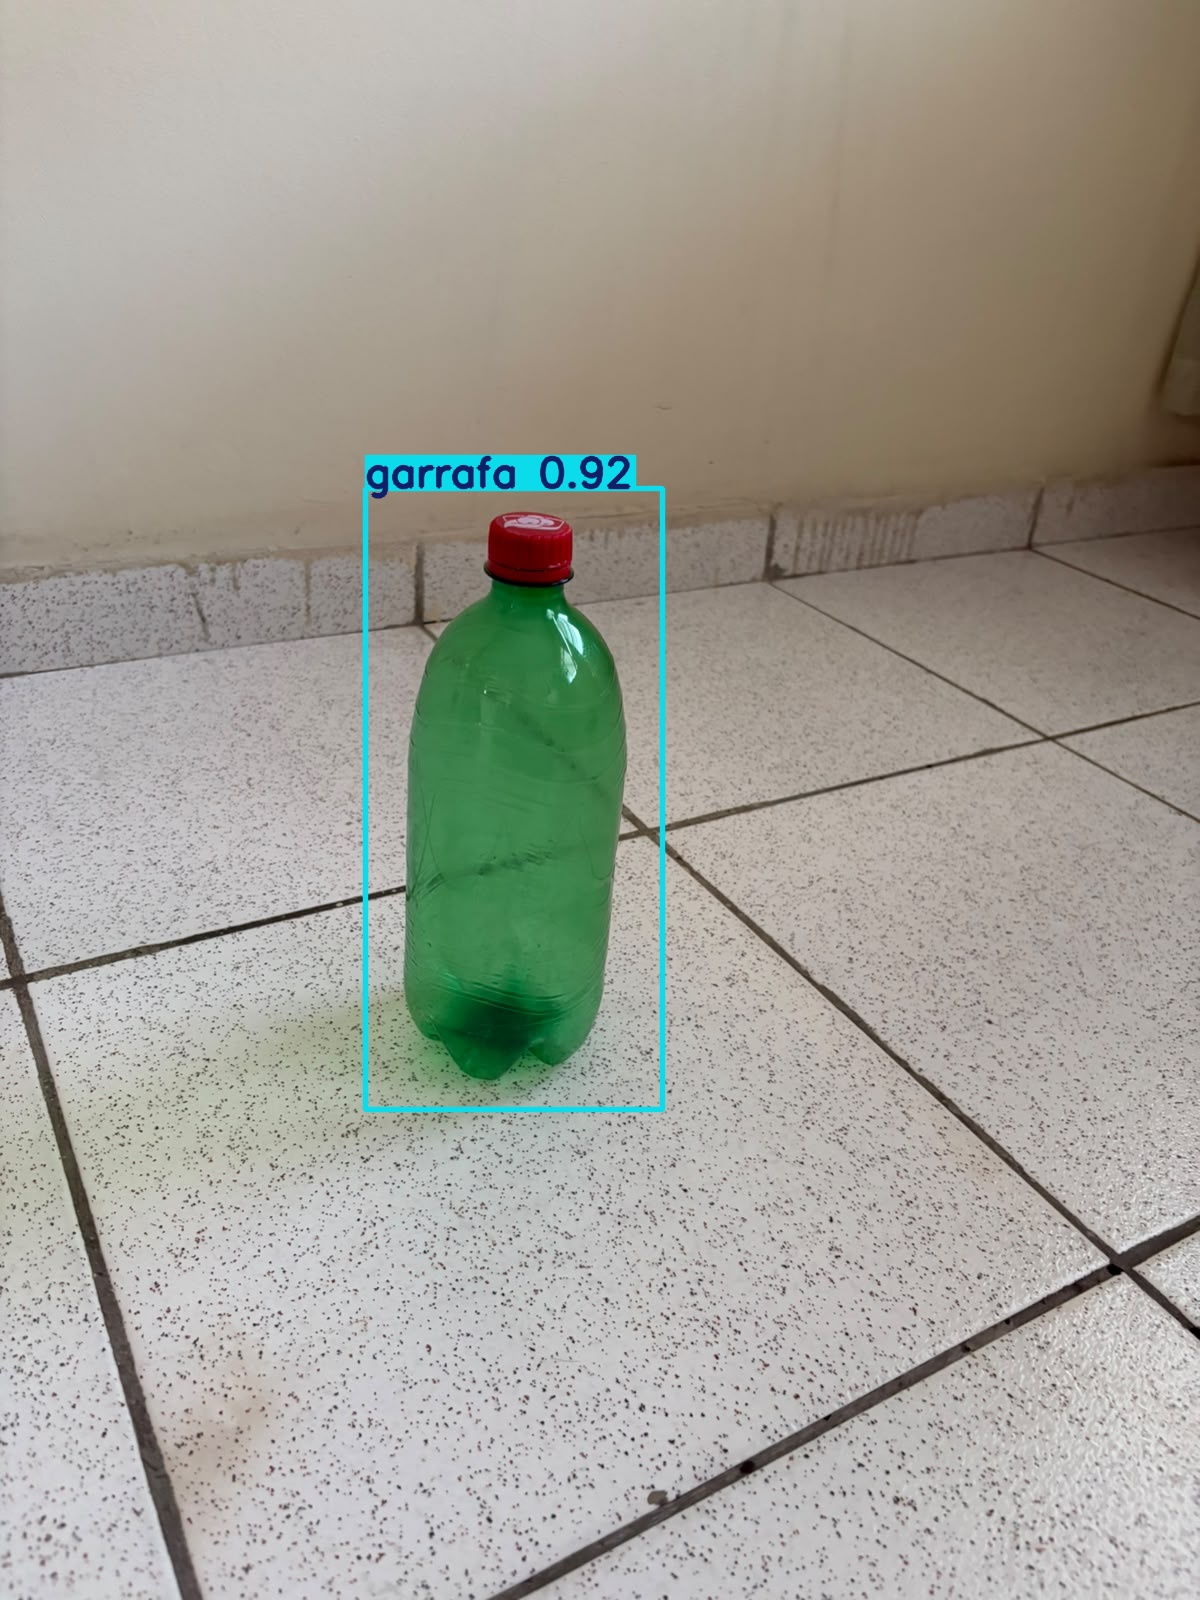

Cópia de WhatsApp Image 2026-10-07 at 17.18.41.jpg


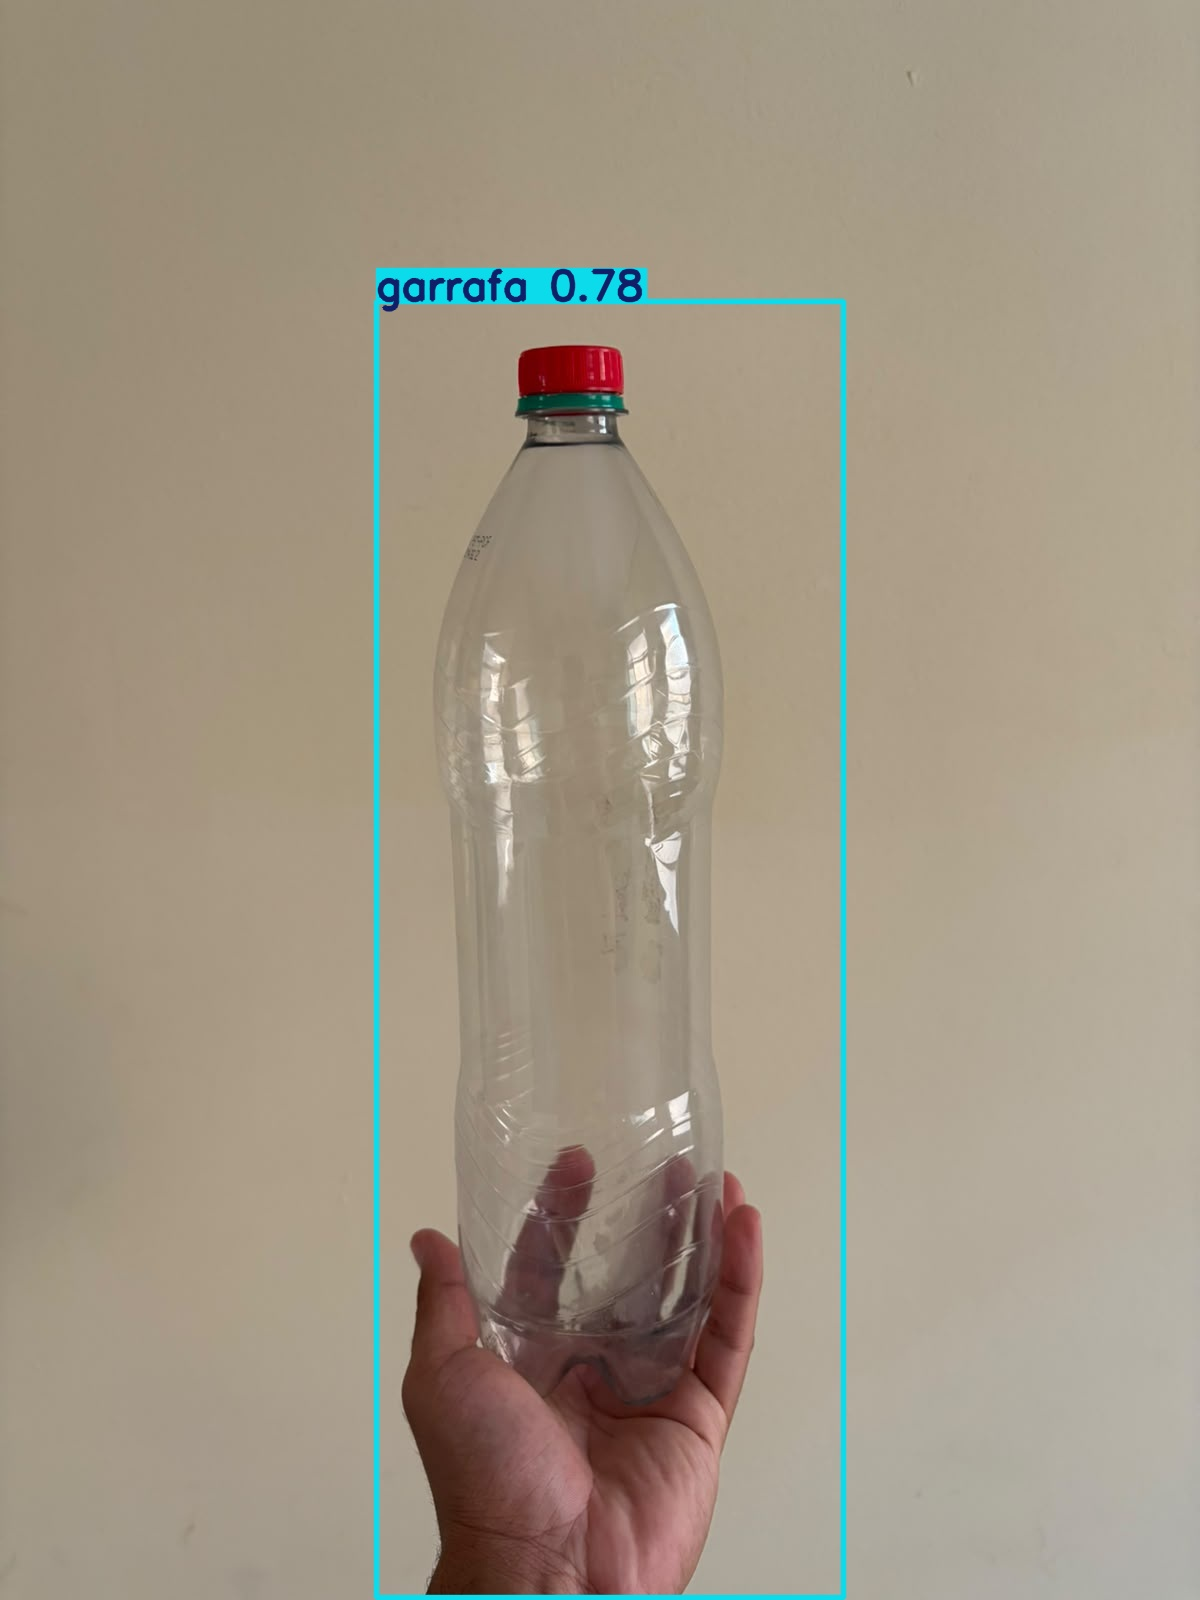

Cópia de WhatsApp Image 2026-10-07 at 17.18.42 (2).jpg


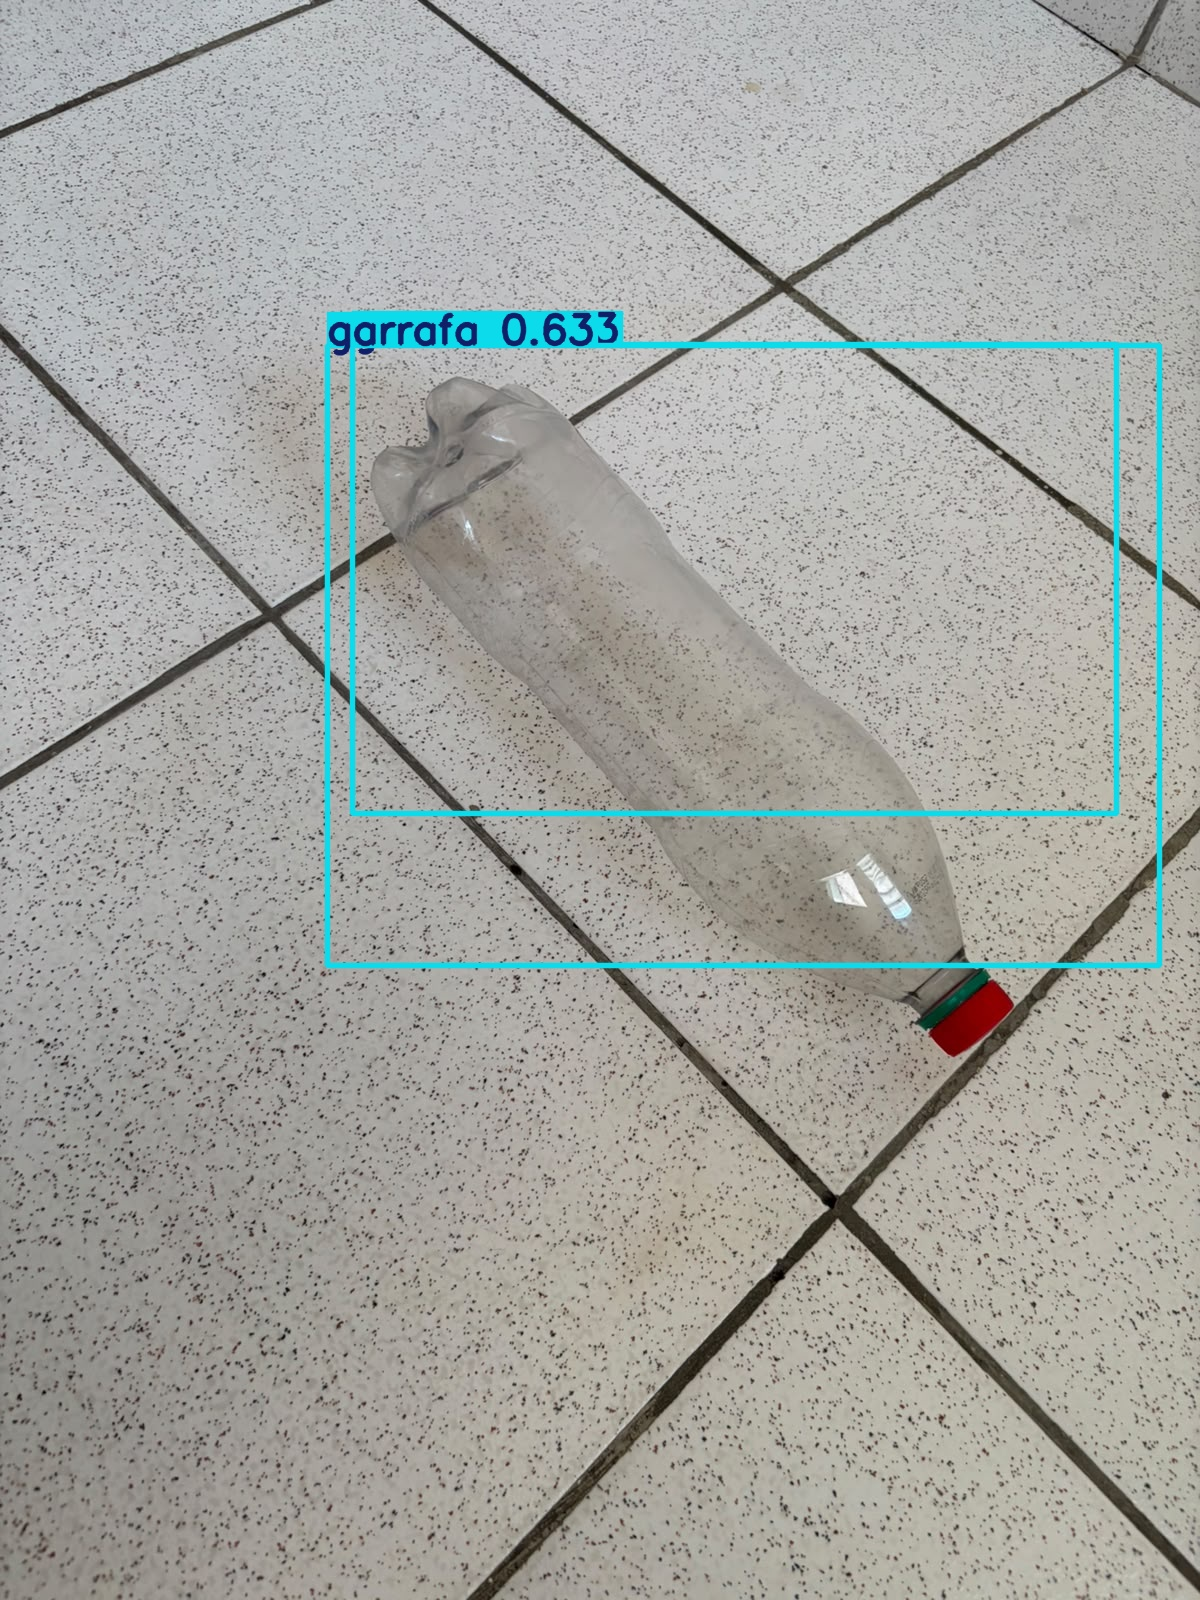

In [ ]:
for arq in sorted(glob.glob(f"{pasta_teste60}/*.jp*g") + glob.glob(f"{pasta_teste60}/*.png")):
    print(os.path.basename(arq))                                 # nome da imagem
    display(Image(arq, width=500))                               # imagem com as caixas desenhadas

### Observações sobre os testes

As 8 imagens de teste não têm rótulo, então a avaliação abaixo foi feita olhando as imagens: quatro são de teclado e quatro de garrafa.

| # | Imagem | 30 épocas | 60 épocas |
|---|---|---|---|
| 1 | Teclado de aparelho portátil | acertou (0,44) | acertou (0,95) |
| 2 | Teclado ao lado de um gato | duas caixas (0,32 e 0,26); uma cobre a parte de cima da cena | uma caixa (0,96) que ocupa quase a imagem inteira |
| 3 | Criança na mesa, teclado pequeno ao fundo | não detectou | não detectou |
| 4 | Teclado com um gato à frente | acertou (0,68) | acertou (0,90), com uma caixa extra (0,29) |
| 5 | Garrafa verde pequena | acertou (0,98) | acertou (0,90) |
| 6 | Garrafa verde em pé | acertou (0,99) | acertou (0,92) |
| 7 | Garrafa transparente na mão | acertou (0,68) | acertou (0,78) |
| 8 | Garrafa transparente deitada no chão | não detectou | acertou (0,63), com uma caixa extra (0,33) |

**Contagem:** com 30 épocas o objeto foi encontrado em **6 das 8** imagens; com 60 épocas, em **7 das 8**.

**O que se observa**
- **Garrafas coloridas e em pé** são detectadas com confiança alta pelos dois modelos.
- **Garrafa transparente deitada** foi o caso mais difícil: só o modelo de 60 épocas a encontrou.
- **Teclado pequeno em uma cena cheia de objetos e pessoas** (imagem 3) não foi detectado por nenhum dos dois.
- **Trade-off:** o modelo de 60 épocas é bem mais confiante, mas produz caixas extras e, na imagem 2, uma caixa pouco justa. O de 30 épocas é menos confiante e, em teclados, desenha caixas menos precisas.
- A imagem 1 é um teclado de aparelho portátil, diferente de um teclado de computador. Foi contada como acerto, mas é um caso ambíguo.
- **Contradição com a validação:** na validação, 30 épocas foram melhores; no teste, 60 épocas acertaram uma imagem a mais. Com apenas 8 imagens em cada conjunto, não dá para decidir entre os dois modelos só com esses números.

## 12. Conclusão

Conseguimos treinar uma YOLO customizada que reconhece **teclado** e **garrafa** a partir de apenas 64 imagens de treino, com treinos de um a dois minutos. A garrafa é detectada com consistência; o teclado é o objeto mais difícil, por variar bastante de forma, ângulo e contexto.

**Resultado da comparação 30 x 60 épocas:** na validação, 30 épocas foram melhores (mAP50 de 0,995 contra 0,912; recall de 0,98 contra 0,75). No teste, 60 épocas acertaram uma imagem a mais (7 de 8 contra 6 de 8), com confianças mais altas, mas também com caixas extras. As duas leituras se contradizem, o que mostra que 8 imagens por conjunto não bastam para declarar um vencedor. O que os dados sustentam é que **treinar por mais tempo não trouxe um ganho claro** e que o treino de 60 épocas mostra sinal leve de overfitting.

**Pontos fortes**
- Treino rápido e simples de repetir, com poucos dados, graças ao uso de pesos pré-treinados.
- Boa detecção da garrafa e bom desempenho geral nos dois treinos (mAP50 acima de 0,9 na validação).
- Fluxo completo e reprodutível: rotulação, treino, validação e teste, com semente fixa e dataset versionado.

**Limitações**
- Dataset pequeno e validação com apenas 8 imagens, o que torna as métricas instáveis: o mesmo experimento de 30 épocas já teve mAP50 diferente em outra execução.
- Sinal leve de overfitting no treino de 60 épocas.
- Falhas em casos difíceis: teclado pequeno no meio de uma cena cheia e garrafa transparente deitada.
- O teste foi avaliado visualmente, porque as imagens de teste não têm rótulo.

**Recomendação:** para este conjunto de dados, **30 épocas já bastam**, com treino mais curto e menos risco de overfitting. Para melhorar os resultados, o caminho mais promissor é **ampliar e diversificar as imagens**, principalmente teclados em cenas reais e garrafas transparentes em várias posições, usar uma validação maior e ajustar o limiar de confiança para reduzir as caixas extras.

In [ ]:
import os
from google.colab import files

print("Pasta existe:", os.path.exists("/content/runs"))   # precisa dar True
!cd /content && zip -rq resultados_entrega1.zip runs        # compacta os resultados
files.download("/content/resultados_entrega1.zip")          # baixa para o computador

Pasta existe: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>